In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load the original Stack Overflow survey dataset
df = pd.read_csv("survey_results_public.csv", low_memory=False)

# Create a separate copy for cleaning
df_clean = df.copy()

print("Original dataset shape:", df.shape)
print("Cleaning dataset shape:", df_clean.shape)

Original dataset shape: (30903, 212)
Cleaning dataset shape: (30903, 212)


In [2]:
columns_to_check = ['Country', 'Employment', 'Education', 'OrgSize']

for col in columns_to_check:
    print(f"\n--- {col} ---")
    print("Unique values:", df_clean[col].nunique())
    print("Missing values:", df_clean[col].isnull().sum())
    print("Sample values:")
    print(df_clean[col].dropna().unique()[:20])


--- Country ---
Unique values: 169
Missing values: 9533
Sample values:
['Sri Lanka' 'Brazil' 'Ukraine' 'United States of America' 'Germany'
 'Sweden' 'Canada' 'Czech Republic' 'Switzerland' 'Hungary'
 'Hong Kong (S.A.R.)'
 'United Kingdom of Great Britain and Northern Ireland' 'Turkey' 'Uruguay'
 'Argentina' 'Netherlands' 'Portugal' 'Australia' 'Belgium' 'Serbia']

--- Employment ---
Unique values: 6
Missing values: 0
Sample values:
['Independent contractor, freelancer, or self-employed' 'Employed'
 'Retired' 'Student' 'Not employed' 'I prefer not to say']

--- Education ---
Unique values: 8
Missing values: 142
Sample values:
["Master's degree (M.A., M.S., M.Eng., MBA, etc.)"
 'Primary/elementary school'
 "Bachelor's degree (B.A., B.S., B.Eng., etc.)"
 'Secondary school (e.g. American high school, German Realschule or Gymnasium, etc.)'
 'Some college/university study without earning a degree'
 'Associate degree (A.A., A.S., etc.)'
 'Professional degree (JD, MD, Ph.D, Ed.D, etc.)' 'Oth

In [3]:
columns_to_check = ['Country', 'Employment', 'Education', 'OrgSize']

for col in columns_to_check:
    print(f"\n--- {col} ---")
    print("Unique values:", df_clean[col].nunique())
    print("Missing values:", df_clean[col].isnull().sum())
    print("Sample values:")
    print(df_clean[col].dropna().unique()[:20])


--- Country ---
Unique values: 169
Missing values: 9533
Sample values:
['Sri Lanka' 'Brazil' 'Ukraine' 'United States of America' 'Germany'
 'Sweden' 'Canada' 'Czech Republic' 'Switzerland' 'Hungary'
 'Hong Kong (S.A.R.)'
 'United Kingdom of Great Britain and Northern Ireland' 'Turkey' 'Uruguay'
 'Argentina' 'Netherlands' 'Portugal' 'Australia' 'Belgium' 'Serbia']

--- Employment ---
Unique values: 6
Missing values: 0
Sample values:
['Independent contractor, freelancer, or self-employed' 'Employed'
 'Retired' 'Student' 'Not employed' 'I prefer not to say']

--- Education ---
Unique values: 8
Missing values: 142
Sample values:
["Master's degree (M.A., M.S., M.Eng., MBA, etc.)"
 'Primary/elementary school'
 "Bachelor's degree (B.A., B.S., B.Eng., etc.)"
 'Secondary school (e.g. American high school, German Realschule or Gymnasium, etc.)'
 'Some college/university study without earning a degree'
 'Associate degree (A.A., A.S., etc.)'
 'Professional degree (JD, MD, Ph.D, Ed.D, etc.)' 'Oth

In [4]:
# Check leading/trailing whitespace
country_values = df_clean['Country'].dropna()

whitespace_values = country_values[
    country_values != country_values.str.strip()
]

print("Values with unnecessary spaces:")
print(whitespace_values.unique())

print("\nNumber of affected responses:", len(whitespace_values))

# Check capitalization patterns
print("\nSample country values:")
print(country_values.sample(min(20, len(country_values)), random_state=42).tolist())

Values with unnecessary spaces:
[]

Number of affected responses: 0

Sample country values:
['United States of America', 'Pakistan', 'Switzerland', 'Mexico', 'United Kingdom of Great Britain and Northern Ireland', 'United States of America', 'Japan', 'Slovenia', 'France', 'Czech Republic', 'Italy', 'Germany', 'India', 'United Kingdom of Great Britain and Northern Ireland', 'Colombia', 'United States of America', 'Canada', 'France', 'United Kingdom of Great Britain and Northern Ireland', 'Belgium']


In [5]:
# Inspect text formatting in Employment and Education

for col in ['Employment', 'Education']:
    values = df_clean[col].dropna()

    print(f"\n--- {col} ---")
    print("Unique values before cleaning:", values.nunique())

    # Check leading/trailing spaces
    spaces = values[values != values.str.strip()]
    print("Responses with extra spaces:", len(spaces))

    # Check lowercase values
    lowercase_values = values[
        values != values.str.strip().str.title()
    ]
    print("Values differing from title case:", len(lowercase_values))

    print("All unique values:")
    print(sorted(values.unique()))


--- Employment ---
Unique values before cleaning: 6
Responses with extra spaces: 0
Values differing from title case: 6898
All unique values:
['Employed', 'I prefer not to say', 'Independent contractor, freelancer, or self-employed', 'Not employed', 'Retired', 'Student']

--- Education ---
Unique values before cleaning: 8
Responses with extra spaces: 0
Values differing from title case: 30761
All unique values:
['Associate degree (A.A., A.S., etc.)', "Bachelor's degree (B.A., B.S., B.Eng., etc.)", "Master's degree (M.A., M.S., M.Eng., MBA, etc.)", 'Other, please specify', 'Primary/elementary school', 'Professional degree (JD, MD, Ph.D, Ed.D, etc.)', 'Secondary school (e.g. American high school, German Realschule or Gymnasium, etc.)', 'Some college/university study without earning a degree']


In [6]:
# Check country names after normalizing whitespace and capitalization

country_normalized = (
    df_clean['Country']
    .dropna()
    .str.strip()
    .str.casefold()
)

print("Original unique countries:",
      df_clean['Country'].nunique())

print("Unique countries after case normalization:",
      country_normalized.nunique())

# Find categories that differ only by capitalization
country_check = pd.DataFrame({
    'original': df_clean['Country'].dropna().unique()
})

country_check['normalized'] = (
    country_check['original'].str.strip().str.casefold()
)

duplicates = country_check[
    country_check.duplicated('normalized', keep=False)
].sort_values('normalized')

print("\nPotential duplicate country labels:")
print(duplicates.to_string(index=False))

Original unique countries: 169
Unique countries after case normalization: 169

Potential duplicate country labels:
Empty DataFrame
Columns: [original, normalized]
Index: []


In [7]:
# Find text columns containing unnecessary whitespace

text_columns = df_clean.select_dtypes(include=['object']).columns

whitespace_report = []

for col in text_columns:
    values = df_clean[col].dropna().astype(str)

    affected = values != values.str.strip()

    if affected.any():
        whitespace_report.append({
            'Column': col,
            'Affected Responses': affected.sum(),
            'Unique Values': values.nunique()
        })

whitespace_df = pd.DataFrame(whitespace_report)

if not whitespace_df.empty:
    display(
        whitespace_df.sort_values(
            by='Affected Responses',
            ascending=False
        )
    )
else:
    print("No unnecessary leading/trailing whitespace found.")

No unnecessary leading/trailing whitespace found.


In [8]:
# Missing-value analysis for selected columns

selected_columns = ['Country', 'Employment', 'Education', 'OrgSize', 'WorkExp']

missing_summary = pd.DataFrame({
    'Missing Count': df_clean[selected_columns].isnull().sum(),
    'Missing Percentage': (
        df_clean[selected_columns].isnull().mean() * 100
    ).round(2)
})

display(missing_summary)

,Missing Count,Missing Percentage
Country,9533,30.85
Employment,0,0.00
Education,142,0.46
OrgSize,9788,31.67
WorkExp,6296,20.37


WorkExp data type: float64

Descriptive statistics:


count    24607.000000
mean        14.257325
std         11.727927
min          1.000000
25%          5.000000
50%         12.000000
75%         20.000000
max        100.000000
Name: WorkExp, dtype: float64


Median: 12.0
Mean: 14.257325151379689


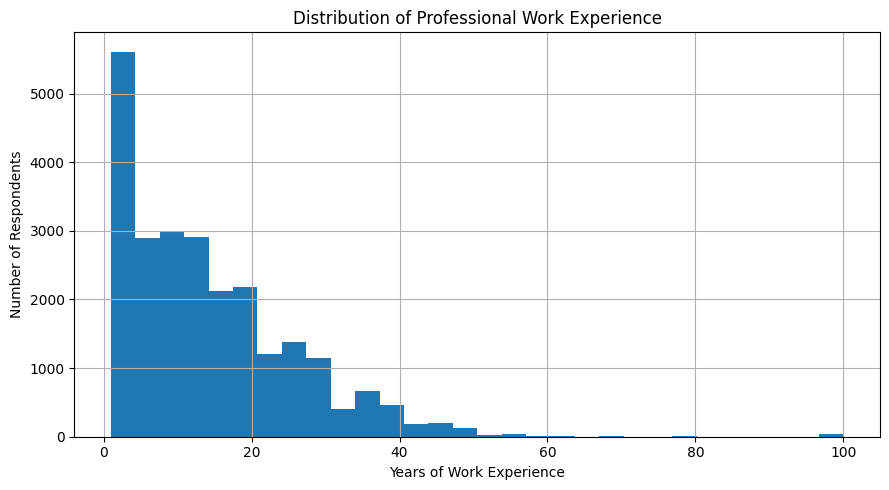

In [9]:

# Inspect WorkExp data type and distribution

print("WorkExp data type:", df_clean['WorkExp'].dtype)

print("\nDescriptive statistics:")
display(df_clean['WorkExp'].describe())

print("\nMedian:", df_clean['WorkExp'].median())
print("Mean:", df_clean['WorkExp'].mean())

# Visualize the distribution
plt.figure(figsize=(9, 5))
df_clean['WorkExp'].dropna().hist(bins=30)

plt.title('Distribution of Professional Work Experience')
plt.xlabel('Years of Work Experience')
plt.ylabel('Number of Respondents')
plt.tight_layout()
plt.show()


### Missing Value Handling Strategy

The dataset contains missing values across several important columns. The following strategies were selected:

| Column | Strategy | Reason |
|---|---|---|
| Country | Fill with `Unknown` | Preserve respondents who did not report their country |
| Employment | No action | No missing values |
| Education | Fill with `Unknown` | Preserve responses without inventing education levels |
| OrgSize | Fill with `Unknown` | Missing organization size cannot be reliably inferred |
| WorkExp | Median imputation (12 years) | The distribution is right-skewed, making the median less sensitive to extreme values |

An additional indicator column, `WorkExp_WasMissing`, will identify records where work experience was originally missing.

The original dataset will remain unchanged, and all cleaning operations will be performed on a separate copy.

In [10]:

# Track originally missing WorkExp values
df_clean['WorkExp_WasMissing'] = df_clean['WorkExp'].isnull()

# Fill missing categorical values
categorical_columns = ['Country', 'Education', 'OrgSize']

for col in categorical_columns:
    df_clean[col] = df_clean[col].fillna('Unknown')

# Fill missing WorkExp using the median
workexp_median = df_clean['WorkExp'].median()

df_clean['WorkExp'] = df_clean['WorkExp'].fillna(workexp_median)

print("Median used for WorkExp:", workexp_median)

# Verify missing values
print("\nMissing values after cleaning:")
print(df_clean[
    ['Country', 'Employment', 'Education', 'OrgSize', 'WorkExp']
].isnull().sum())


Median used for WorkExp: 12.0

Missing values after cleaning:
Country       0
Employment    0
Education     0
OrgSize       0
WorkExp       0
dtype: int64


In [11]:

# Define experience categories
bins = [0, 5, 15, float('inf')]

labels = ['Junior', 'Mid', 'Senior']

# Create the new feature
df_clean['ExperienceLevel'] = pd.cut(
    df_clean['WorkExp'],
    bins=bins,
    labels=labels,
    include_lowest=True
)

# Inspect the new feature
print("Experience level distribution:")
print(df_clean['ExperienceLevel'].value_counts())

print("\nSample records:")
display(df_clean[['WorkExp', 'ExperienceLevel']].head(10))


Experience level distribution:
ExperienceLevel
Mid       14996
Senior     9086
Junior     6821
Name: count, dtype: int64

Sample records:


,WorkExp,ExperienceLevel
0,12.0,Mid
1,26.0,Senior
2,37.0,Senior
3,1.0,Junior
4,26.0,Senior
5,26.0,Senior
6,5.0,Junior
7,5.0,Junior
8,3.0,Junior
9,35.0,Senior


In [12]:

print("Expected categories:")
print(df_clean['ExperienceLevel'].cat.categories.tolist())

print("\nMissing values:")
print(df_clean['ExperienceLevel'].isnull().sum())

print("\nUnique categories:")
print(df_clean['ExperienceLevel'].unique())


Expected categories:
['Junior', 'Mid', 'Senior']

Missing values:
0

Unique categories:
['Mid', 'Senior', 'Junior']
Categories (3, object): ['Junior' < 'Mid' < 'Senior']


In [13]:

# Select categorical columns for encoding
encoding_columns = ['Employment', 'Education', 'ExperienceLevel']

# Apply one-hot encoding
encoded_df = pd.get_dummies(
    df_clean[encoding_columns],
    prefix=encoding_columns,
    dtype=int
)

# Display encoded data
print("Original categorical columns:")
display(df_clean[encoding_columns].head())

print("\nEncoded columns:")
display(encoded_df.head())

print("\nNumber of encoded columns:", encoded_df.shape[1])


Original categorical columns:


,Employment,Education,ExperienceLevel
0,"Independent contractor, freelancer, or self-em...","Master's degree (M.A., M.S., M.Eng., MBA, etc.)",Mid
1,Employed,"Master's degree (M.A., M.S., M.Eng., MBA, etc.)",Senior
2,Retired,"Master's degree (M.A., M.S., M.Eng., MBA, etc.)",Senior
3,Student,Primary/elementary school,Junior
4,Employed,"Bachelor's degree (B.A., B.S., B.Eng., etc.)",Senior



Encoded columns:


,Employment_Employed,Employment_I prefer not to say,"Employment_Independent contractor, freelancer, or self-employed",Employment_Not employed,Employment_Retired,Employment_Student,"Education_Associate degree (A.A., A.S., etc.)","Education_Bachelor's degree (B.A., B.S., B.Eng., etc.)","Education_Master's degree (M.A., M.S., M.Eng., MBA, etc.)","Education_Other, please specify",Education_Primary/elementary school,"Education_Professional degree (JD, MD, Ph.D, Ed.D, etc.)","Education_Secondary school (e.g. American high school, German Realschule or Gymnasium, etc.)",Education_Some college/university study without earning a degree,Education_Unknown,ExperienceLevel_Junior,ExperienceLevel_Mid,ExperienceLevel_Senior
0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0
1,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1
2,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,1
3,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,1,0,0
4,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1



Number of encoded columns: 18


In [14]:

# Compare average work experience by employment status
# Exclude originally missing WorkExp values

valid_workexp = df_clean[
    df_clean['WorkExp_WasMissing'] == False
]

cleaned_group_comparison = (
    valid_workexp.groupby('Employment')['WorkExp']
    .agg(['mean', 'count'])
    .sort_values('mean', ascending=False)
)

cleaned_group_comparison['mean'] = (
    cleaned_group_comparison['mean'].round(2)
)

print("Average Work Experience by Employment Status:")
display(cleaned_group_comparison)


Average Work Experience by Employment Status:


,mean,count
Employment,,
Retired,36.02,518
"Independent contractor, freelancer, or self-employed",18.10,3793
I prefer not to say,16.78,259
Employed,14.03,17207
Not employed,11.09,1209
Student,2.66,1621


In [15]:

# Combine cleaned numerical features with one-hot encoded columns

df_model = pd.concat(
    [
        df_clean.drop(columns=encoding_columns),
        encoded_df
    ],
    axis=1
)

print("Cleaned dataset shape:", df_clean.shape)
print("Model-ready dataset shape:", df_model.shape)

display(df_model.head())


Cleaned dataset shape: (30903, 214)
Model-ready dataset shape: (30903, 229)


,ResponseId,Age,CodeMain,EmploymentAddl,ICorPM,WorkSetting,LearnCode,LearnCodeHow,LearnAI,LearnAIHow,...,"Education_Master's degree (M.A., M.S., M.Eng., MBA, etc.)","Education_Other, please specify",Education_Primary/elementary school,"Education_Professional degree (JD, MD, Ph.D, Ed.D, etc.)","Education_Secondary school (e.g. American high school, German Realschule or Gymnasium, etc.)",Education_Some college/university study without earning a degree,Education_Unknown,ExperienceLevel_Junior,ExperienceLevel_Mid,ExperienceLevel_Senior
0,1,35-44 years old,I create code as a primary part of my job,None of the above,Individual contributor in a senior or staff-le...,"Hybrid (some remote, leans heavy to in-person)",Yes,AI codegen tools or AI-enabled apps,"Yes, on my own",Games or coding challenges,...,1,0,0,0,0,0,0,0,1,0
1,2,45-54 years old,I create code as a primary part of my job,"Caring for dependents (children, elderly, etc.)",Individual contributor,Remote,No,NaN,"Yes, on my own",AI CodeGen tools or AI-enabled apps,...,1,0,0,0,0,0,0,0,0,1
2,3,65 years or older,I create code as a primary part of my job,Volunteering (regularly),NaN,NaN,No,NaN,No,NaN,...,1,0,0,0,0,0,0,0,0,1
3,4,Under 18 years old,I create code as a primary part of my job,Attending school (full-time);Volunteering (reg...,NaN,NaN,Yes,AI codegen tools or AI-enabled apps;Colleague ...,"Yes, on my own",AI CodeGen tools or AI-enabled apps;Colleague ...,...,0,0,1,0,0,0,0,1,0,0
4,5,45-54 years old,I create code as a primary part of my job,None of the above,Individual contributor in a senior or staff-le...,Remote,No,NaN,"Yes, both on my own and at work",AI CodeGen tools or AI-enabled apps,...,0,0,0,0,0,0,0,0,0,1


In [16]:

from pathlib import Path

# Create data folder if it doesn't exist
data_folder = Path("data")
data_folder.mkdir(exist_ok=True)

# Save cleaned dataset
output_path = data_folder / "survey_clean.csv"

df_clean.to_csv(output_path, index=False)

print("File saved successfully!")
print("File location:", output_path)
print("Saved dataset shape:", df_clean.shape)


File saved successfully!
File location: data/survey_clean.csv
Saved dataset shape: (30903, 214)


In [17]:

# Load the saved CSV
df_verified = pd.read_csv("data/survey_clean.csv", low_memory=False)

print("Original cleaned shape:", df_clean.shape)
print("Reloaded CSV shape:", df_verified.shape)

print("\nColumn count:", len(df_verified.columns))

print("\nMissing values in selected columns:")
print(
    df_verified[
        ['Country', 'Employment', 'Education', 'OrgSize', 'WorkExp']
    ].isnull().sum()
)

print("\nNew engineered columns:")
print(df_verified[
    ['WorkExp_WasMissing', 'ExperienceLevel']
].head())


Original cleaned shape: (30903, 214)
Reloaded CSV shape: (30903, 214)

Column count: 214

Missing values in selected columns:
Country       0
Employment    0
Education     0
OrgSize       0
WorkExp       0
dtype: int64

New engineered columns:
   WorkExp_WasMissing ExperienceLevel
0                True             Mid
1               False          Senior
2               False          Senior
3               False          Junior
4               False          Senior


In [18]:

def clean_categories(df):
    cleaned = df.copy()

    # Standardize whitespace and capitalization
    # for Country using an explicit mapping dictionary.
    country_mapping = {
        'sri lanka': 'Sri Lanka',
        'united states of america': 'United States of America'
    }

    cleaned['Country'] = (
        cleaned['Country']
        .str.strip()
        .str.lower()
        .map(country_mapping)
        .fillna(cleaned['Country'])
    )

    return cleaned


# Apply function to the original dataset copy
df_function_test = clean_categories(df.copy())

print("Function executed successfully.")
print("Original rows:", len(df))
print("Cleaned rows:", len(df_function_test))


Function executed successfully.
Original rows: 30903
Cleaned rows: 30903


In [19]:

print("Country unique values before cleaning:",
      df['Country'].nunique())

print("Country unique values after cleaning:",
      df_function_test['Country'].nunique())


Country unique values before cleaning: 169
Country unique values after cleaning: 169


### Category Standardization Findings

The Country column initially contained 169 unique values. Inspection found no leading or trailing whitespace and no categories that differed only by capitalization. A reusable `clean_categories(df)` function was implemented using Pandas string methods and a mapping dictionary.

After applying the function, the number of unique country categories remained 169. This indicates that the inspected country labels were already consistently formatted, so no reduction in unique categories was necessary.

In [22]:
# Find possible duplicate categories after normalization

text_columns = df.select_dtypes(include='object').columns

for col in text_columns:
    values = df[col].dropna().astype(str)

    normalized = values.str.strip().str.casefold()

    comparison = pd.DataFrame({
        'Original': values,
        'Normalized': normalized
    }).drop_duplicates()

    duplicates = comparison[
        comparison.duplicated('Normalized', keep=False)
    ]

    if not duplicates.empty:
        print(f"\n--- {col} ---")
        print(duplicates.sort_values('Normalized').to_string(index=False))

In [23]:
# Find text columns with potentially useful category values

text_columns = df.select_dtypes(include='object').columns

for col in text_columns:
    unique_count = df[col].nunique(dropna=True)

    if 10 <= unique_count <= 500:
        print(f"\nColumn: {col}")
        print(f"Unique values: {unique_count}")
        print(df[col].dropna().unique()[:15])


Column: EmploymentAddl
Unique values: 173
['None of the above' 'Caring for dependents (children, elderly, etc.)'
 'Volunteering (regularly)'
 'Attending school (full-time);Volunteering (regularly)'
 'Engaged in paid work (20-29 hours per week);Volunteering (regularly)'
 'Attending school (full-time)'
 'Engaged in paid work (20-29 hours per week);None of the above'
 'Transitioning to retirement (gradually reducing work hours)'
 'Caring for dependents (children, elderly, etc.);Transitioning to retirement (gradually reducing work hours)'
 'Caring for dependents (children, elderly, etc.);Engaged in paid work (20-29 hours per week);Volunteering (regularly)'
 'Attending school (part-time)'
 'Engaged in paid work (10-19 hours per week)'
 'Caring for dependents (children, elderly, etc.);Volunteering (regularly)'
 'Attending school (full-time);Engaged in paid work (less than 10 hours per week)'
 'Engaged in paid work (less than 10 hours per week)']

Column: Role
Unique values: 41
['Developer, 

In [24]:
# Check whether EmploymentAddl has different orderings
# of the same selected options

def normalize_employment_addl(value):
    if pd.isna(value):
        return value

    mapping = {
        item.strip().lower(): item.strip()
        for item in value.split(';')
    }

    return ';'.join(sorted(mapping.values(), key=str.lower))


before_count = df['EmploymentAddl'].nunique()

after_count = (
    df['EmploymentAddl']
    .apply(normalize_employment_addl)
    .nunique()
)

print("Unique responses before cleaning:", before_count)
print("Unique responses after cleaning:", after_count)
print("Reduction:", before_count - after_count)

Unique responses before cleaning: 173
Unique responses after cleaning: 173
Reduction: 0


In [25]:
def has_duplicate_selections(value):
    if pd.isna(value):
        return False

    items = [item.strip().lower() for item in value.split(';')]
    return len(items) != len(set(items))


duplicate_rows = df[
    df['EmploymentAddl'].apply(has_duplicate_selections)
]

print("Responses containing duplicate selections:", len(duplicate_rows))

if not duplicate_rows.empty:
    print(duplicate_rows['EmploymentAddl'].head(10).to_string(index=False))

Responses containing duplicate selections: 0


In [26]:
# Search for columns that may contain free-text responses

keywords = ['other', 'specify', 'please', 'comment', 'describe']

for col in df.columns:
    if any(word in col.lower() for word in keywords):
        print(
            f"{col}: "
            f"{df[col].nunique(dropna=True)} unique values"
        )

In [27]:
# Inspect text columns with the highest number of unique responses

text_columns = df.select_dtypes(include='object').columns

column_summary = pd.DataFrame({
    'Column': text_columns,
    'Unique_Values': [df[col].nunique() for col in text_columns],
    'Missing_Values': [df[col].isna().sum() for col in text_columns]
})

column_summary = column_summary.sort_values(
    by='Unique_Values',
    ascending=False
)

display(column_summary.head(20))

,Column,Unique_Values,Missing_Values
48,CloudPlatHaveWorkedWith,9215,20144
38,LanguagesHaveWorkedWith,8413,16979
12,RoleFunctions,7430,6189
97,AIWorkExpectMore,6659,20714
39,LanguagesWantToWorkWith,6530,19946
49,CloudPlatWantToWorkWith,6430,22653
96,AIWorkCurrentlyUse,6399,19693
50,CloudPlatAdmired,5613,23389
54,DevIDEHaveWorkedWith,5096,17783
40,LanguagesUsedAI,4965,21006


In [28]:
# Inspect RoleFunctions responses

print("Unique values:", df['RoleFunctions'].nunique())
print("\nSample responses:")

for value in df['RoleFunctions'].dropna().unique()[:30]:
    print(repr(value))

Unique values: 7430

Sample responses:
'Writing or updating documentation'
'Answering questions from teammates, customers, users, or stakeholders;Debugging or troubleshooting;Finding or fixing security, privacy, or compliance issues;Investigating an incident, outage, or production issue;Maintaining dependencies, packages, or development environments;Making technical design or architecture decisions;Planning, scoping, or estimating work;Reviewing code, pull requests, or technical changes;Writing, editing, or generating code'
'Writing, editing, or generating code'
'Answering questions from teammates, customers, users, or stakeholders;Changing production code, systems, or infrastructure;Coordinating work across teams or functions;Debugging or troubleshooting;Deploying or releasing software;Making technical design or architecture decisions;Planning, scoping, or estimating work;Reviewing code, pull requests, or technical changes;Writing or maintaining tests;Writing or updating documentation

In [29]:
# Extract individual RoleFunctions options

all_options = (
    df['RoleFunctions']
    .dropna()
    .str.split(';')
    .explode()
    .dropna()
)

print("Number of individual options:", all_options.nunique())

print("\nAll individual options:")
for option in sorted(all_options.unique()):
    print(repr(option))

Number of individual options: 18

All individual options:
'Analyzing data, reports, or business metrics'
'Answering questions from teammates, customers, users, or stakeholders'
'Changing production code, systems, or infrastructure'
'Coordinating work across teams or functions'
'Debugging or troubleshooting'
'Deploying or releasing software'
'Finding or fixing security, privacy, or compliance issues'
'Investigating an incident, outage, or production issue'
'Maintaining dependencies, packages, or development environments'
'Making technical design or architecture decisions'
'Monitoring systems, logs, metrics, or alerts'
'None of the above'
'Onboarding to a new project, tool, system, or codebase'
'Planning, scoping, or estimating work'
'Reviewing code, pull requests, or technical changes'
'Writing or maintaining tests'
'Writing or updating documentation'
'Writing, editing, or generating code'


In [30]:
# Display all country categories

for country in sorted(df['Country'].dropna().unique()):
    print(repr(country))

'Afghanistan'
'Albania'
'Algeria'
'Andorra'
'Angola'
'Antigua and Barbuda'
'Argentina'
'Armenia'
'Australia'
'Austria'
'Azerbaijan'
'Bahrain'
'Bangladesh'
'Barbados'
'Belarus'
'Belgium'
'Benin'
'Bolivia'
'Bosnia and Herzegovina'
'Botswana'
'Brazil'
'Brunei Darussalam'
'Bulgaria'
'Burkina Faso'
'Burundi'
'Cambodia'
'Cameroon'
'Canada'
'Central African Republic'
'Chad'
'Chile'
'China'
'Colombia'
'Congo, Republic of the...'
'Costa Rica'
'Croatia'
'Cuba'
'Cyprus'
'Czech Republic'
"Côte d'Ivoire"
"Democratic People's Republic of Korea"
'Democratic Republic of the Congo'
'Denmark'
'Dominican Republic'
'Ecuador'
'Egypt'
'El Salvador'
'Estonia'
'Ethiopia'
'Fiji'
'Finland'
'France'
'Gambia'
'Georgia'
'Germany'
'Ghana'
'Greece'
'Guatemala'
'Guyana'
'Haiti'
'Honduras'
'Hong Kong (S.A.R.)'
'Hungary'
'Iceland'
'India'
'Indonesia'
'Iran, Islamic Republic of...'
'Iraq'
'Ireland'
'Isle of Man'
'Israel'
'Italy'
'Jamaica'
'Japan'
'Jordan'
'Kazakhstan'
'Kenya'
'Kosovo'
'Kuwait'
'Kyrgyzstan'
"Lao People's

In [31]:
# Standardize country names using a mapping dictionary

def clean_categories(df):
    cleaned = df.copy()

    country_mapping = {
        'south korea': 'South Korea',
        'republic of korea': 'South Korea',
        'north korea': 'North Korea',
        "democratic people's republic of korea": 'North Korea',
        'moldova': 'Moldova',
        'republic of moldova': 'Moldova'
    }

    original = cleaned['Country'].astype('string').str.strip()
    normalized = original.str.lower()

    cleaned['Country'] = normalized.map(country_mapping).fillna(original)

    return cleaned

In [32]:
# Apply the cleaning function
df_country_cleaned = clean_categories(df)

# Compare unique country counts
before_count = df['Country'].nunique()
after_count = df_country_cleaned['Country'].nunique()

print("Unique countries before cleaning:", before_count)
print("Unique countries after cleaning:", after_count)
print("Reduction:", before_count - after_count)

# Display standardized country names
print("\nStandardized country names:")
print(
    df_country_cleaned['Country']
    .value_counts()
    .loc[['South Korea', 'North Korea', 'Moldova']]
)

Unique countries before cleaning: 169
Unique countries after cleaning: 166
Reduction: 3

Standardized country names:
Country
South Korea    51
North Korea     6
Moldova        14
Name: count, dtype: int64


In [33]:
# Apply country standardization to the main cleaned dataset

df_clean = clean_categories(df_clean)

print("Country categories before cleaning:", df['Country'].nunique())
print("Country categories after cleaning:", df_clean['Country'].nunique())

print("\nMissing values in selected columns:")
print(df_clean[['Country', 'Employment', 'Education',
                'OrgSize', 'WorkExp']].isnull().sum())

Country categories before cleaning: 169
Country categories after cleaning: 167

Missing values in selected columns:
Country       0
Employment    0
Education     0
OrgSize       0
WorkExp       0
dtype: int64


In [34]:
# Final country standardization comparison

raw_unique = df['Country'].nunique(dropna=True)

cleaned_unique = (
    df_clean.loc[df_clean['Country'] != 'Unknown', 'Country']
    .nunique()
)

print("Unique countries before cleaning:", raw_unique)
print("Unique countries after cleaning:", cleaned_unique)
print("Reduction:", raw_unique - cleaned_unique)

print("\nMissing values in selected columns:")
print(
    df_clean[
        ['Country', 'Employment', 'Education', 'OrgSize', 'WorkExp']
    ].isnull().sum()
)

Unique countries before cleaning: 169
Unique countries after cleaning: 166
Reduction: 3

Missing values in selected columns:
Country       0
Employment    0
Education     0
OrgSize       0
WorkExp       0
dtype: int64


In [35]:
from pathlib import Path

# Create data folder if it doesn't exist
data_folder = Path("data")
data_folder.mkdir(exist_ok=True)

# Export updated cleaned dataset
output_path = data_folder / "survey_clean.csv"
df_clean.to_csv(output_path, index=False)

print("Cleaned dataset saved successfully!")
print("Shape:", df_clean.shape)

Cleaned dataset saved successfully!
Shape: (30903, 214)


In [ ]:
# Reload exported dataset
df_verified = pd.read_csv("data/survey_clean.csv", low_memory=False)

print("Original cleaned DataFrame shape:", df_clean.shape)
print("Reloaded CSV shape:", df_verified.shape)

print("\nSelected columns missing values:")
print(
    df_verified[
        ['Country', 'Employment', 'Education', 'OrgSize', 'WorkExp']
    ].isnull().sum()
)

print("\nExperienceLevel categories:")
print(df_verified['ExperienceLevel'].unique())